In [ ]:
# pip install imbalanced-learn

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import numpy as np
import pandas as pd

# 生成不平衡数据集

0    1000
1     100
dtype: int64

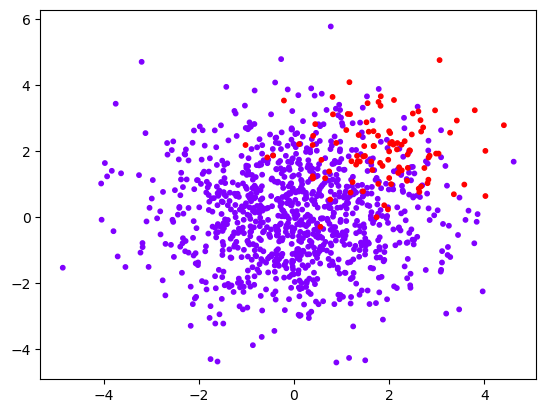

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
class_1 = 1000       #类别1有1000个样本
class_2 = 100        #类别2只有100个
centers = [[0,0], [2.0, 2.0]]         #设定两个类别的中心
clusters_std = [1.5, 1]             #设定两个类别的标准差，通常来说，样本量比较大的类别会更加松散
X, y = make_blobs(n_samples= [class_1, class_2],
                  centers= centers,
                  cluster_std= clusters_std,
                  random_state= 42, shuffle= False)
# 画图看数据集，其中红色点是少数类，紫色点是多数类
plt.scatter(X[:, 0], X[:, 1], c = y, cmap = "rainbow",s = 10)
# 查看不平衡的样本数量
pd.DataFrame(y).value_counts()

# Over-sampling 过采样
最简单的过采样方法是对少数类别样本做简单复制，例如sklearn库中的calss_weight参数采用的就是此方法。  
进阶的过采样方法为插值法（interpolation），主要有**SMOTE**和**ADASYN**两种方法。需要注意的是，插值法可能会在多数类样本中间插值出一个少数类样本导致类别重叠。  
## SMOTE
全称Synthetic Minority Oversampling Technique.  
算法如下：  
1. 计算采样比例N，（默认N= 多数样本量/少数样本量）
2. 对每一个少数类样本$x_i$，从其k近邻个少数类样本中有放回地随机抽样N-1个，记为$x_{ik}$。  
3. 分别与原样本$x_i$按照如下的公式生成新的插值样本  
$$x_{new}=x_i+rand(0,1)*(x_i-x_{ik})$$  

重复进行，直到满足停止条件。  
参考文献：Nitesh V Chawla, Kevin W Bowyer, Lawrence O Hall, and W Philip Kegelmeyer. Smote: synthetic minority over-sampling technique. Journal of artificial intelligence research, 16:321–357, 2002.  

In [3]:
# SMOTE过采样
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 42, sampling_strategy= 0.5)
X_sm, Y_sm = smote.fit_resample(X, y)

# 查看采样后的比例
pd.DataFrame(Y_sm).value_counts()

# 画图看过采样后的数据集
plt.scatter(X_sm[:, 0], X_sm[:, 1], c = Y_sm, cmap = "rainbow",s = 10)

ModuleNotFoundError: No module named 'imblearn'

# Under-sampling欠采样
## Controlled under-sampling
常用的是Random under-sampling，即随机删除多数类样本。这是唯一一种可以精确设置欠采样样本数量的常用欠采样算法，因此冠以Controlled名号。

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


0    333
1    100
dtype: int64

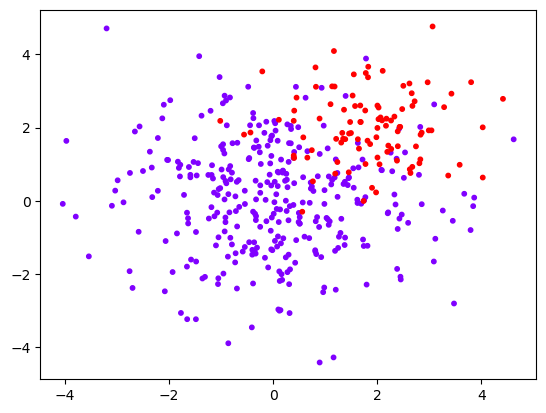

In [7]:
# Random欠采样
from imblearn.under_sampling import RandomUnderSampler

rus= RandomUnderSampler(sampling_strategy=0.3, random_state= 42)
X_rus, Y_rus = rus.fit_resample(X, y)

# 查看采样后的比例
pd.DataFrame(Y_rus).value_counts()

# 画图看过采样后的数据集
plt.scatter(X_rus[:, 0], X_rus[:, 1], c = Y_rus, cmap = "rainbow",s = 10)

## Cleaning under-sampling
Cleaning类的欠采样算法无法精确控制欠采样样本的数量
### TomekLinks
当多数类的某样本y和少数类的某样本x，与另外任意样本z，之间的距离d()存在以下关系
$$d(x,y)<d(x,z)\qquad and\qquad d(x,y)<d(y,z)$$
则称x与y之间存在Tomek Link，此时算法可删除多数类样本y以实现欠采样。  
可以发现，TomekLinks算法不适合对有清晰边界的两类样本做欠采样。  
参考文献：Ivan Tomek. Two modifications of cnn. IEEE Trans. Systems, Man and Cybernetics, 6:769–772, 1976.

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


0    969
1    100
dtype: int64

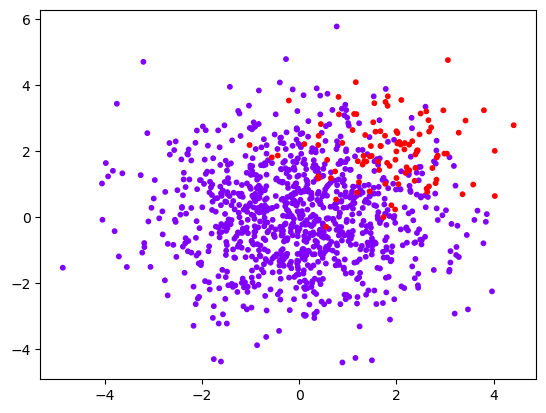

In [8]:
# TomekLinks欠采样
from imblearn.under_sampling import TomekLinks

tl= TomekLinks()
X_tl, Y_tl= tl.fit_resample(X, y)

# 查看采样后的比例
pd.DataFrame(Y_tl).value_counts()

# 画图看过采样后的数据集
plt.scatter(X_tl[:, 0], X_tl[:, 1], c = Y_tl, cmap = "rainbow",s = 10)

### Edited nearest neighbours
算法思路是应用最近邻算法来编辑(edit)数据集, 找出那些与邻居不太友好的样本然后移除。  
具体来说，对每一个多数类样本$x_i$，若其k近邻的全部/大多数样本是多数类，则该多数类样本$x_i$会被保留，否则会被移除。  
参考文献：Dennis L Wilson. Asymptotic properties of nearest neighbor rules using edited data. IEEE Transactions on Systems, Man, and Cybernetics, pages 408–421, 1972.

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


0    695
1    100
dtype: int64

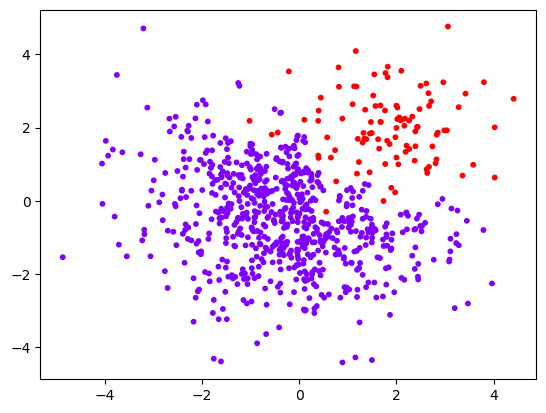

In [9]:
# ENN欠采样
from imblearn.under_sampling import EditedNearestNeighbours

enn= EditedNearestNeighbours(n_neighbors= 20)  # 改变n_neighbors=3 参数以观察欠采样结果
X_enn, Y_enn= enn.fit_resample(X, y)

# 查看采样后的比例
pd.DataFrame(Y_enn).value_counts()

# 画图看过采样后的数据集
plt.scatter(X_enn[:, 0], X_enn[:, 1], c = Y_enn, cmap = "rainbow",s = 10)

# Combination sampling联合采样

如果多数类样本有离群值，SMOTE等过采样方法容易在多数类样本中间错误地插入少数类插值，导致类别重叠。这些问题插值可以通过联合使用欠采样方法来解决。  
这里我们分别将Tomeks link和Edited nearest-neighbours联接在SMOTE之后，来清除过采样生成的问题插值，以得到一个尽量干净的数据空间。

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


0    948
1    948
dtype: int64

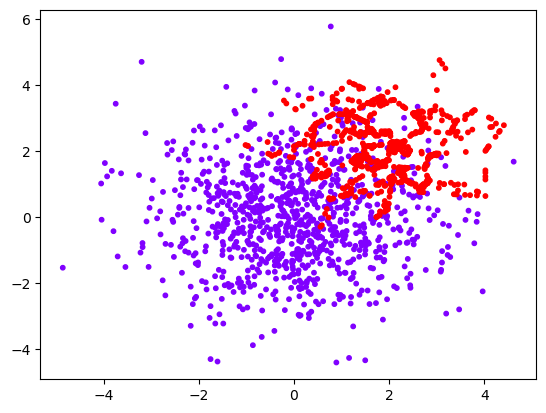

In [10]:
# SMOTE叠加TomekLink
from imblearn.combine import SMOTETomek

smote_tomek = SMOTETomek(random_state= 42)
X_smote_tomek, Y_smote_tomek= smote_tomek.fit_resample(X, y)

# 查看采样后的比例
pd.DataFrame(Y_smote_tomek).value_counts()

# 画图看过采样后的数据集
plt.scatter(X_smote_tomek[:, 0], X_smote_tomek[:, 1], c = Y_smote_tomek, cmap = "rainbow",s = 10)

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


0    794
1    789
dtype: int64

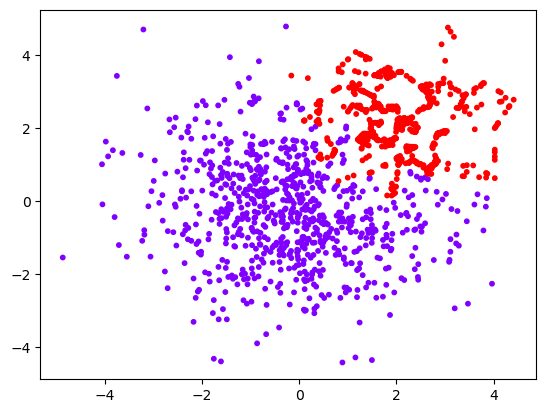

In [11]:
# SMOTE叠加ENN
from imblearn.combine import SMOTEENN

smote_enn = SMOTEENN(random_state= 42)
X_smote_enn, Y_smote_enn= smote_enn.fit_resample(X, y)

# 查看采样后的比例
pd.DataFrame(Y_smote_enn).value_counts()

# 画图看过采样后的数据集
plt.scatter(X_smote_enn[:, 0], X_smote_enn[:, 1], c = Y_smote_enn, cmap = "rainbow",s = 10)

# 实践问题

## 不做过采样

In [12]:
# 读取数据
raw_data= pd.read_csv('train_set.csv')

In [13]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18987 entries, 0 to 18986
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         18987 non-null  int64  
 1   age        18944 non-null  float64
 2   job        18987 non-null  object 
 3   marital    18987 non-null  object 
 4   education  18987 non-null  object 
 5   default    18651 non-null  object 
 6   balance    18987 non-null  int64  
 7   housing    18987 non-null  object 
 8   loan       18939 non-null  object 
 9   contact    18987 non-null  object 
 10  day        18987 non-null  int64  
 11  month      18987 non-null  object 
 12  duration   18987 non-null  int64  
 13  campaign   18987 non-null  int64  
 14  pdays      18987 non-null  int64  
 15  previous   18987 non-null  int64  
 16  poutcome   18987 non-null  object 
 17  y          18987 non-null  int64  
dtypes: float64(1), int64(8), object(9)
memory usage: 2.6+ MB


In [14]:
df_features= raw_data.drop(['ID'], axis=1)

In [15]:
df= df_features.dropna().reset_index(drop= True)  # 缺失值
labels= df.pop("y")  # 分割标签
cat_cols= df.select_dtypes(include= ["object"])   # 分类型
num_cols= df.select_dtypes(exclude= ["object"])   # 数值型
# 数据编码
from sklearn.preprocessing import OrdinalEncoder
encoder= OrdinalEncoder()
cat_trans= encoder.fit_transform(cat_cols)
df_cat= pd.DataFrame(cat_trans, columns= cat_cols.columns)
# 数据合并
data= pd.concat([df_cat, num_cols], axis=1)
# 分割测试集
from sklearn.model_selection  import train_test_split
Xtrain, Xtest, Ytrain, Ytest= train_test_split(data, labels, test_size= 0.3, stratify= labels, random_state= 42)

In [16]:
import xgboost as xgb
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

train = xgb.DMatrix(data= Xtrain, label= Ytrain)
XGB= xgb.train(params= {}, dtrain= train)

test = xgb.DMatrix(data= Xtest)
print(classification_report(Ytest, XGB.predict(test)>0.5))
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

              precision    recall  f1-score   support

           0       0.92      0.97      0.95      4913
           1       0.63      0.38      0.47       655

    accuracy                           0.90      5568
   macro avg       0.77      0.68      0.71      5568
weighted avg       0.89      0.90      0.89      5568

AUC:  0.9111332607212832


## 过采样

In [17]:
# SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 42)
X_sm, Y_sm = smote.fit_resample(Xtrain, Ytrain)

# 查看采样后的比例
pd.DataFrame(Y_sm).value_counts()

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


y
0    11465
1    11465
dtype: int64

In [18]:
train_sm = xgb.DMatrix(data= X_sm, label= Y_sm)
XGB= xgb.train(params= {}, dtrain= train_sm)

test_sm = xgb.DMatrix(data= Xtest)
print(classification_report(Ytest, XGB.predict(test_sm)>0.5))
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test_sm)))

              precision    recall  f1-score   support

           0       0.95      0.92      0.93      4913
           1       0.50      0.61      0.55       655

    accuracy                           0.88      5568
   macro avg       0.72      0.76      0.74      5568
weighted avg       0.89      0.88      0.89      5568

AUC:  0.9065663149488117


In [19]:
# 思考：上述过采样得到的数据，是否有问题

In [20]:
# SMOTENC
from imblearn.over_sampling import SMOTENC

smote_nc= SMOTENC(categorical_features= list(cat_cols.columns))
X_smnc, Y_smnc = smote_nc.fit_resample(Xtrain, Ytrain)

# 查看采样后的比例
pd.DataFrame(Y_smnc).value_counts()

C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
C:\Users\15587\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


y
0    11465
1    11465
dtype: int64

In [21]:
train_smnc = xgb.DMatrix(data= X_smnc, label= Y_smnc)
XGB= xgb.train(params= {}, dtrain= train_smnc)

print(classification_report(Ytest, XGB.predict(test_sm)>0.5))
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test_sm)))

              precision    recall  f1-score   support

           0       0.96      0.87      0.91      4913
           1       0.42      0.73      0.53       655

    accuracy                           0.85      5568
   macro avg       0.69      0.80      0.72      5568
weighted avg       0.90      0.85      0.87      5568

AUC:  0.8964801282778359


## 通过参数解决（XGBoost）

如果关心预测的整体性能指标 (AUC)，可以使用过采样。例如SMOTE等方法。

XGBoost提供了参数scale_pos_weight= 1。正类样本的损失会乘以该权重，从而加大其在梯度计算中的贡献。更有效地解决类别不平衡问题

In [22]:
weight= Ytrain.value_counts()[0] / Ytrain.value_counts()[1]

params= {'scale_pos_weight': weight, 'eval_metric': 'auc'}

XGB= xgb.train(params= params, dtrain= train)

print(classification_report(Ytest, XGB.predict(test)>0.5))
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

              precision    recall  f1-score   support

           0       0.97      0.84      0.90      4913
           1       0.41      0.82      0.55       655

    accuracy                           0.84      5568
   macro avg       0.69      0.83      0.73      5568
weighted avg       0.91      0.84      0.86      5568

AUC:  0.9095088121093283


如果关心预测正确的概率，此时若重新平衡数据集，会改变标签的分布，可能会影响模型投产后的预测效果。在这种情况下，不推荐重新平衡数据集。

XGBoost提供了参数max_delta_step= 0。通过控制控制权重更新步长的范围，来防止类别不平衡导致的极端的梯度更新

In [23]:
params= {'max_delta_step': 0.6, 'eval_metric': 'auc'}

XGB= xgb.train(params= params, dtrain= train)

print(classification_report(Ytest, XGB.predict(test)>0.5))
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

              precision    recall  f1-score   support

           0       0.93      0.97      0.94      4913
           1       0.61      0.42      0.50       655

    accuracy                           0.90      5568
   macro avg       0.77      0.69      0.72      5568
weighted avg       0.89      0.90      0.89      5568

AUC:  0.9120961213667432


LightGBM虽然也提供了类似参数，但LightGBM更依赖学习率和正则化参数（如lambda_l2）来控制梯度更新的幅度和训练稳定性，而不直接使用类似于 max_delta_step 的参数。